# Instructions

1. Première FFT
    - Créer un sinus à $f_1=100Hz$, échantillonné à $f_s=48kHz$, calculer sa FFT et la tracer
    - Déphaser le sinus de $\pi/4$ puis de $\pi/2$, comprendre l'évolution du tracé de la FFT

2. Filtrage
    - Créer un signal composé de deux sinus, à $f_1=100Hz$ et $f_2=500Hz$
    - Utiliser la FFT pour filtrer la composante à $500Hz$ et ne garder que celle à $100Hz$
    - Tracer la FFT avant et après filtrage
    - Revenir dans le domaine temporel, écouter et tracer le résultat

3. Modulation
    - Créer deux sinus à $f_1=1kHz$ et $f_2=100Hz$, les multiplier
    - Tracer et écouter le résultat $x$, calculer et tracer sa FFT
    - Recréer un signal qui a le même spectre que $x$ en sommant deux sinus (sans multiplication)
    - Démontrer l'équivalence identifiée à l'aide de la formule d'Euler

# Correction

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from IPython.display import Audio
import scipy

## 1. Première FFT

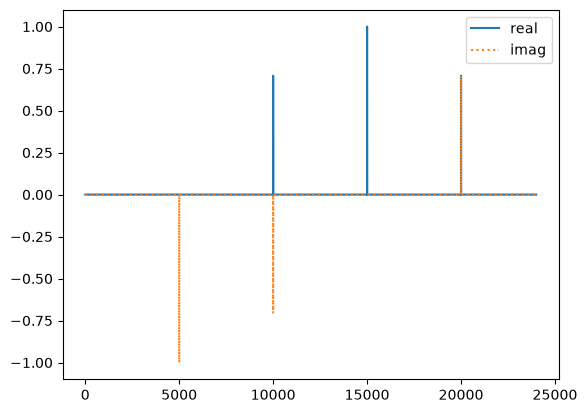

In [2]:
# init locals
fs = 48000

# create sine
duration_in_sec = 1
t = np.arange(duration_in_sec * fs) / fs
f1 = 5000; x = np.sin(2*math.pi*f1*t)
f2 = 10000; x += np.sin(2*math.pi*f2*t + math.pi/4)
f3 = 15000; x += np.sin(2*math.pi*f3*t + math.pi/2)
f4 = 20000; x += np.sin(2*math.pi*f4*t + 3*math.pi/4)

# fft
n = len(x)
X = np.fft.rfft(x, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs)

# plot
plt.plot(f, np.real(X), label = 'real')
plt.plot(f, np.imag(X), ':', label = 'imag')

# format plot
plt.legend()
plt.show()

## 2. Filtrage

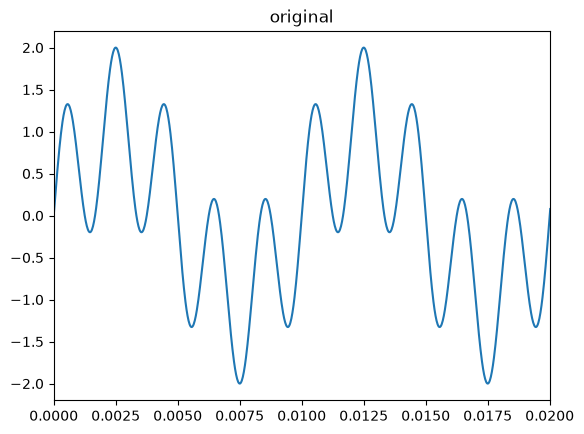

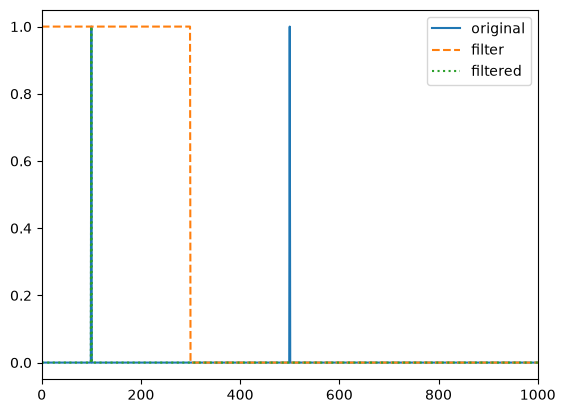

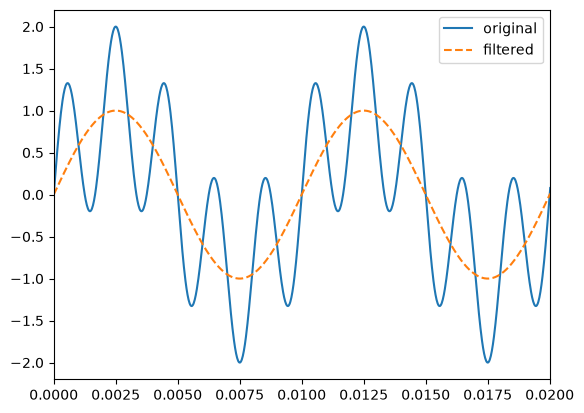

In [4]:
# create sine
f1, f2 = 100, 500
x = np.sin(2*math.pi*f1*t) + np.sin(2*math.pi*f2*t)

# play 
display(Audio(x, rate=fs))

# plot
plt.plot(t, x)
plt.title('original')
plt.xlim([0, 2/f1])
plt.show()

# fft
n = len(x)
X = np.fft.rfft(x, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs)

# filter
W = np.zeros(len(X))
W[f < 300] = 1
Y = W * X

# plot
plt.plot(f, np.abs(X), label = 'original')
plt.plot(f, np.abs(W), label = 'filter', linestyle = '--')
plt.plot(f, np.abs(Y), label = 'filtered', linestyle = ':')
plt.xlim([0, 2*f2])
plt.legend()
plt.show()

# ifft
y = np.fft.irfft(Y, n) * (n/2)

# plot
plt.plot(t, x, label = 'original')
plt.plot(t, y, label = 'filtered', linestyle = '--')

# format plot
plt.xlim([0, 2/f1])
plt.legend()
plt.show()

# play 
display(Audio(y, rate=fs))


## 3. Modulation

In [ ]:
# init locals
fs = 48000

# create sine
duration_in_sec = 1
t = np.arange(int(duration_in_sec*fs)) / fs
f1, f2 = 1000, 100
x1 = np.sin(2*math.pi*f1*t)
x2 = np.sin(2*math.pi*f2*t)
x = x1 * x2
# x = np.sin(2*math.pi*(f1-f2)*t) + np.sin(2*math.pi*(f1+f2)*t) 

# play
display(Audio(x, rate=fs))

# plot
plt.plot(t, x1, label='base')
plt.plot(t, x2, label='modulation')
plt.plot(t, x, label='result')
plt.xlim([0, 2/f2])
plt.legend()
plt.show()

# rfft
n = fs
X = np.fft.rfft(x, n) / (n/2)
f = np.fft.rfftfreq(n, 1/fs)

# plot
plt.plot(f, np.abs(X))
plt.xlim([0, 5000])
plt.show()